# Employee Attrition: Predicting Who Is Likely to Leave

## 1. Business problem

Losing an employee is expensive: recruiting, onboarding and the loss of experience add up, and a high turnover also hurts the remaining team. An HR team usually learns that someone is leaving only when the resignation arrives, when it is too late to act.

**Question:** which employees have the highest risk of leaving, and what factors are associated with it?

**Why data and Machine Learning help:** the company already stores information about each employee (role, income, overtime, satisfaction, tenure). A model can learn the combination of factors that separates people who left from people who stayed, rank the current employees by risk and let HR focus a limited retention budget on the right people instead of treating everyone equally. Descriptive analysis alone cannot do this ranking, because many factors act together.

**Target:** `Attrition` (1 = left, 0 = stayed). It is a binary classification problem with imbalanced classes.

## 2. Data collection

- **Dataset:** IBM HR Analytics Employee Attrition & Performance
- **Source:** public repository https://github.com/IBM/employee-attrition-aif360 (file `data/emp_attrition.csv`). The same data is also available on Kaggle.
- **Nature of the data:** fictional dataset created by IBM data scientists for educational purposes. It contains no real employees and no confidential information.
- **Size:** 1,470 employees and 35 columns (demographics, job information, income, satisfaction scores and tenure).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, confusion_matrix, RocCurveDisplay
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv('../data/hr_employee_attrition.csv')
df.shape

(1470, 35)

In [3]:
df.isnull().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(0))

In [4]:
df['Attrition'].value_counts(normalize=True)

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64

The data has no missing values and no duplicated rows. Only **16.1%** of the employees left, so the classes are imbalanced. A model that always predicts "stayed" would reach about 84% accuracy and be useless, so accuracy is not used here. The metrics are ROC-AUC, average precision (PR-AUC), recall and precision.

## 3. Exploratory data analysis

In [5]:
df.describe().T[['mean', 'min', 'max']]

,mean,min,max
Age,36.923810,18.0,60.0
DailyRate,802.485714,102.0,1499.0
DistanceFromHome,9.192517,1.0,29.0
Education,2.912925,1.0,5.0
EmployeeCount,1.000000,1.0,1.0
EmployeeNumber,1024.865306,1.0,2068.0
EnvironmentSatisfaction,2.721769,1.0,4.0
HourlyRate,65.891156,30.0,100.0
JobInvolvement,2.729932,1.0,4.0
JobLevel,2.063946,1.0,5.0


In [6]:
df.nunique()[df.nunique() == 1]

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64

`EmployeeCount`, `Over18` and `StandardHours` have a single value and carry no information. `EmployeeNumber` is only an identifier. These four columns are removed in the preprocessing step.

In [7]:
df['Attrition_flag'] = (df['Attrition'] == 'Yes').astype(int)

for col in ['OverTime', 'BusinessTravel', 'MaritalStatus', 'StockOptionLevel']:
    print(df.groupby(col)['Attrition_flag'].mean().round(3).sort_values(ascending=False), '\n')

OverTime
Yes    0.305
No     0.104
Name: Attrition_flag, dtype: float64 

BusinessTravel
Travel_Frequently    0.249
Travel_Rarely        0.150
Non-Travel           0.080
Name: Attrition_flag, dtype: float64 

MaritalStatus
Single      0.255
Married     0.125
Divorced    0.101
Name: Attrition_flag, dtype: float64 

StockOptionLevel
0    0.244
3    0.176
1    0.094
2    0.076
Name: Attrition_flag, dtype: float64 



In [8]:
df.groupby('JobRole')['Attrition_flag'].mean().round(3).sort_values(ascending=False)

JobRole
Sales Representative         0.398
Laboratory Technician        0.239
Human Resources              0.231
Sales Executive              0.175
Research Scientist           0.161
Healthcare Representative    0.069
Manufacturing Director       0.069
Manager                      0.049
Research Director            0.025
Name: Attrition_flag, dtype: float64

In [9]:
df['IncomeBand'] = pd.cut(df['MonthlyIncome'], [0, 3000, 5000, 8000, 20000], labels=['< 3k', '3k-5k', '5k-8k', '> 8k'])
df['AgeBand'] = pd.cut(df['Age'], [17, 25, 35, 45, 60], labels=['18-25', '26-35', '36-45', '46-60'])
df.groupby('IncomeBand')['Attrition_flag'].mean().round(3), df.groupby('AgeBand')['Attrition_flag'].mean().round(3)

(IncomeBand
 < 3k     0.286
 3k-5k    0.141
 5k-8k    0.100
 > 8k     0.105
 Name: Attrition_flag, dtype: float64,
 AgeBand
 18-25    0.358
 26-35    0.191
 36-45    0.092
 46-60    0.125
 Name: Attrition_flag, dtype: float64)

**Main findings of the EDA**

- Employees working overtime leave at **30.5%**, against **10.4%** of those who do not.
- **Sales Representatives** have the highest turnover by role (**39.8%**), while Research Directors and Managers are the most stable (below 5%).
- Turnover is highest among the youngest (**35.8%** up to 25 years old) and the lowest paid (**28.6%** below 3k a month).
- Single employees (**25.5%**), frequent travelers (**24.9%**) and people with no stock options (**24.4%**) also leave more.

These patterns are shown in the figure below, which is the main visualization of the project.

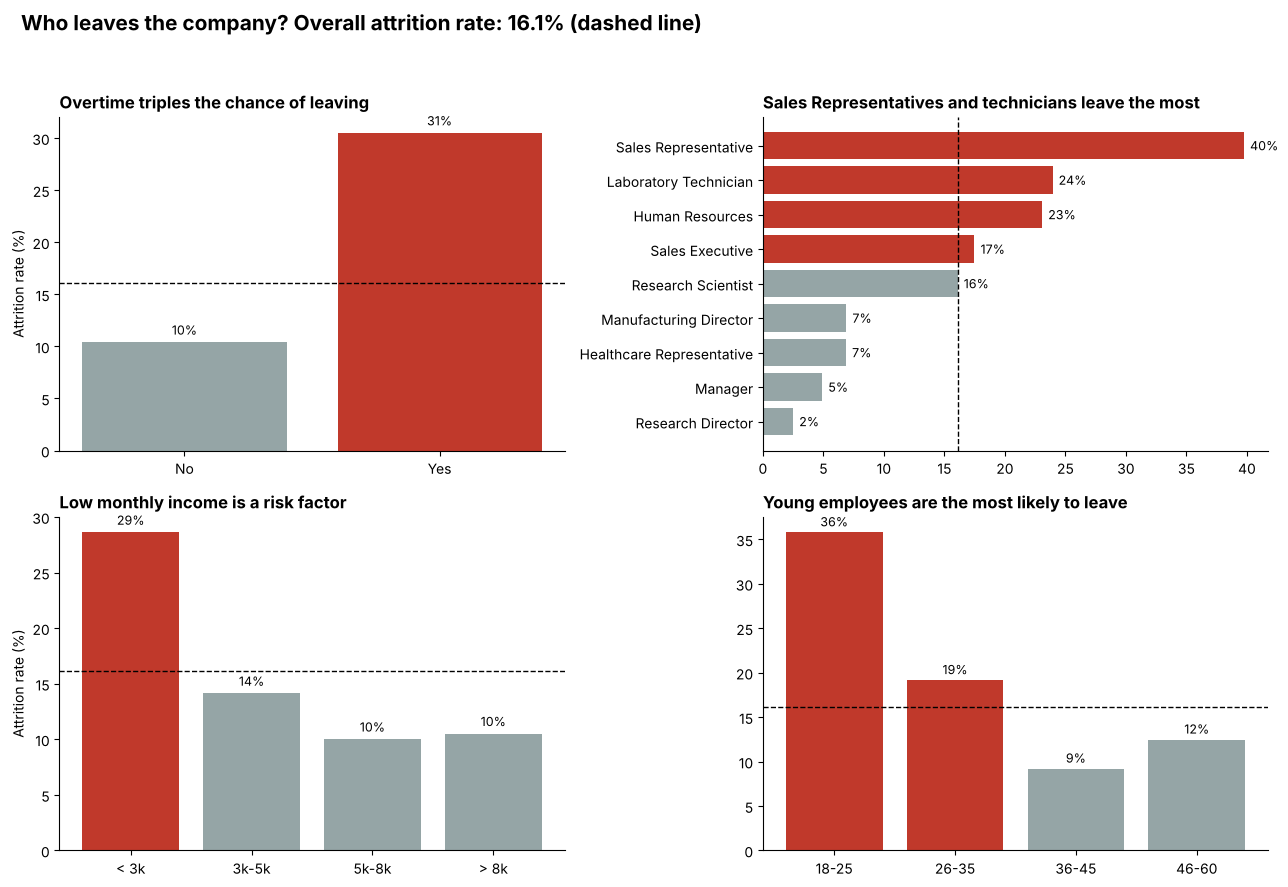

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
overall = df['Attrition_flag'].mean() * 100
palette = {True: '#C0392B', False: '#95A5A6'}

def rate_plot(ax, series_rates, title, horizontal=False):
    rates = series_rates * 100
    colors = ['#C0392B' if r > overall else '#95A5A6' for r in rates]
    if horizontal:
        ax.barh(rates.index.astype(str), rates.values, color=colors)
        ax.axvline(overall, color='black', linestyle='--', linewidth=1)
        ax.invert_yaxis()
        for i, v in enumerate(rates.values): ax.text(v + 0.5, i, f'{v:.0f}%', va='center', fontsize=9)
    else:
        ax.bar(rates.index.astype(str), rates.values, color=colors)
        ax.axhline(overall, color='black', linestyle='--', linewidth=1)
        for i, v in enumerate(rates.values): ax.text(i, v + 0.7, f'{v:.0f}%', ha='center', fontsize=9)
    ax.set_title(title, loc='left', fontweight='bold')
    for s in ['top', 'right']: ax.spines[s].set_visible(False)

rate_plot(axes[0, 0], df.groupby('OverTime')['Attrition_flag'].mean(), 'Overtime triples the chance of leaving')
rate_plot(axes[0, 1], df.groupby('JobRole')['Attrition_flag'].mean().sort_values(ascending=False), 'Sales Representatives and technicians leave the most', horizontal=True)
rate_plot(axes[1, 0], df.groupby('IncomeBand')['Attrition_flag'].mean(), 'Low monthly income is a risk factor')
rate_plot(axes[1, 1], df.groupby('AgeBand')['Attrition_flag'].mean(), 'Young employees are the most likely to leave')
for ax in axes.flat: ax.set_ylabel('')
axes[0, 0].set_ylabel('Attrition rate (%)'); axes[1, 0].set_ylabel('Attrition rate (%)')
fig.suptitle(f'Who leaves the company? Overall attrition rate: {overall:.1f}% (dashed line)', fontsize=15, fontweight='bold', x=0.02, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../images/attrition_drivers.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Preprocessing

- Constant columns and the identifier are removed.
- The data is split into **80% train and 20% test, stratified by the target**, before any fitting. The test set is only used once, at the end.
- Scaling and one-hot encoding are placed inside a scikit-learn `Pipeline`, so they are fitted only on the training folds during cross-validation. This avoids **data leakage**.
- The imbalance is handled with `class_weight='balanced'` (logistic regression and decision tree) and `scale_pos_weight` (XGBoost). SMOTE is not used: the minority class has 16% of the data, which is a moderate imbalance, and class weights keep the test data untouched and the pipeline simple.

In [11]:
df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber', 'Attrition_flag', 'IncomeBand', 'AgeBand'])
df['Attrition'] = (df['Attrition'] == 'Yes').astype(int)

X = df.drop(columns='Attrition')
y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(1176, 30) (294, 30) 0.162 0.16


In [12]:
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes('number').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 5. Modeling

Three models are compared against a baseline that ignores the features:

- **Logistic Regression:** simple, interpretable, linear.
- **Decision Tree:** simple, interpretable, non-linear.
- **XGBoost:** gradient boosting of trees, usually the strongest on tabular data.

All models are evaluated with **stratified 5-fold cross-validation on the training set**, so the choice of the best model does not depend on one lucky split.

In [13]:
models = {
    'Baseline (dummy)': DummyClassifier(strategy='prior'),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    r = cross_validate(pipe, X_train, y_train, cv=skf, scoring=['roc_auc', 'average_precision', 'recall', 'precision'])
    rows.append({'model': name, 'roc_auc': r['test_roc_auc'].mean(), 'roc_auc_std': r['test_roc_auc'].std(),
                 'pr_auc': r['test_average_precision'].mean(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean()})
cv_baseline = pd.DataFrame(rows).set_index('model').round(3)
cv_baseline

,roc_auc,roc_auc_std,pr_auc,recall,precision
model,,,,,
Baseline (dummy),0.500,0.000,0.162,0.000,0.000
Logistic Regression,0.827,0.028,0.606,0.737,0.372
Decision Tree,0.626,0.046,0.305,0.468,0.261
XGBoost,0.799,0.028,0.582,0.553,0.510


The decision tree is clearly the weakest model (ROC-AUC 0.63): a single tree overfits easily on 1,176 training rows. **Logistic regression (0.827) and XGBoost (0.799) are close**, with a difference smaller than the fold-to-fold variation (about 0.03). The next step tunes the hyperparameters of the three models to check if the order changes.

## 6. Hyperparameter tuning

In [14]:
searches = {
    'Logistic Regression': GridSearchCV(
        Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
        {'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, scoring='roc_auc', cv=skf),
    'Decision Tree': RandomizedSearchCV(
        Pipeline([('prep', preprocessor), ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))]),
        {'model__max_depth': [2, 3, 4, 5, 6, 8], 'model__min_samples_leaf': [5, 10, 20, 40], 'model__min_samples_split': [2, 10, 20, 40]},
        n_iter=30, scoring='roc_auc', cv=skf, random_state=42),
    'XGBoost': RandomizedSearchCV(
        Pipeline([('prep', preprocessor), ('model', XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42))]),
        {'model__n_estimators': [100, 200, 300, 500], 'model__max_depth': [2, 3, 4, 5], 'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
         'model__subsample': [0.6, 0.8, 1.0], 'model__colsample_bytree': [0.5, 0.7, 1.0], 'model__min_child_weight': [1, 3, 5]},
        n_iter=40, scoring='roc_auc', cv=skf, random_state=42, n_jobs=-1),
}

for name, search in searches.items():
    search.fit(X_train, y_train)
    print(name, '| best CV ROC-AUC:', round(search.best_score_, 3), '|', search.best_params_)

Logistic Regression | best CV ROC-AUC: 0.831 | {'model__C': 0.1}


Decision Tree | best CV ROC-AUC: 0.724 | {'model__min_samples_split': 40, 'model__min_samples_leaf': 10, 'model__max_depth': 4}


XGBoost | best CV ROC-AUC: 0.824 | {'model__subsample': 0.6, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.5}


Tuning improves the tree (0.63 to 0.72) and XGBoost (0.80 to 0.82) but the ranking stays the same: **logistic regression has the best cross-validated ROC-AUC (0.831)**, followed very closely by XGBoost (0.824) and then the decision tree (0.724). With only 1,470 rows and mostly linear relationships, a regularized linear model is hard to beat, and it is the easiest to explain to an HR team. It is selected as the final model, using only the cross-validation results.

## 7. Final evaluation on the test set

The three tuned models are evaluated once on the 294 employees of the test set, which were never used for training or tuning.

In [15]:
rows, probs = [], {}
for name, search in searches.items():
    p = search.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append({'model': name, 'roc_auc': roc_auc_score(y_test, p), 'pr_auc': average_precision_score(y_test, p),
                 'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred), 'f1': f1_score(y_test, pred)})
test_results = pd.DataFrame(rows).set_index('model').round(3)
test_results

,roc_auc,pr_auc,recall,precision,f1
model,,,,,
Logistic Regression,0.812,0.588,0.681,0.381,0.489
Decision Tree,0.708,0.331,0.553,0.289,0.380
XGBoost,0.805,0.562,0.638,0.455,0.531


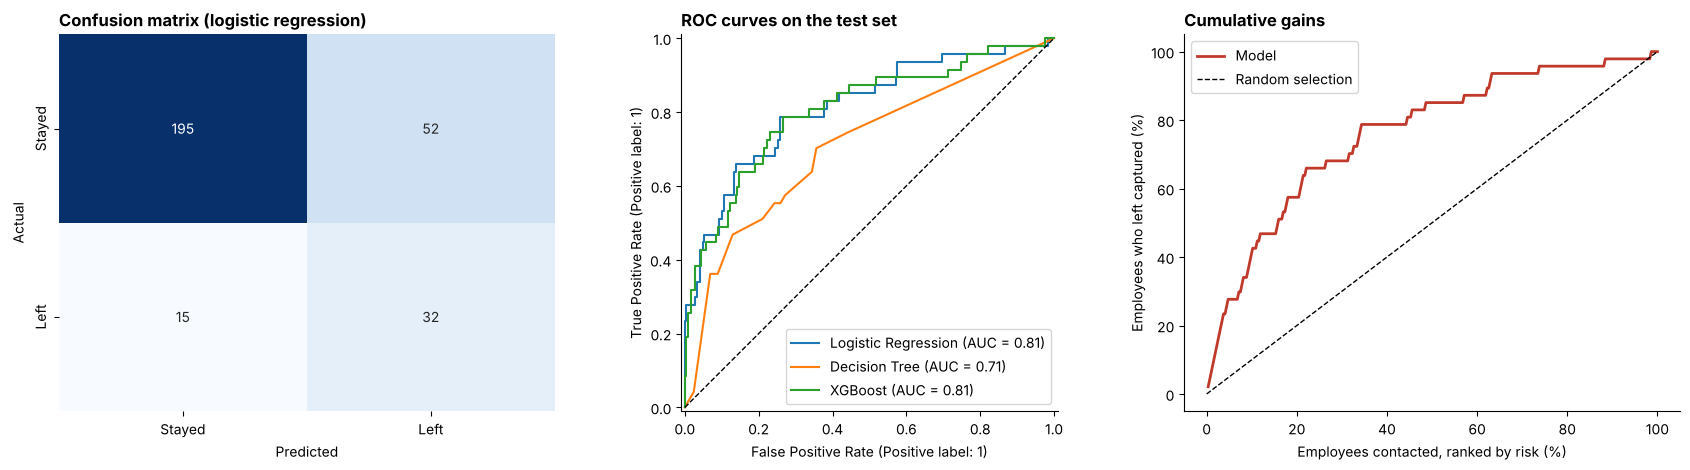

Share of leavers captured by the top 20% highest-risk employees: 0.574


In [16]:
best = searches['Logistic Regression']
pred = (probs['Logistic Regression'] >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Stayed', 'Left'], yticklabels=['Stayed', 'Left'])
axes[0].set_title('Confusion matrix (logistic regression)', loc='left', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].set_title('ROC curves on the test set', loc='left', fontweight='bold')

order = np.argsort(-probs['Logistic Regression'])
captured = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(y_test) + 1) / len(y_test)
axes[2].plot(share * 100, captured * 100, color='#C0392B', linewidth=2, label='Model')
axes[2].plot([0, 100], [0, 100], 'k--', linewidth=1, label='Random selection')
axes[2].set_xlabel('Employees contacted, ranked by risk (%)'); axes[2].set_ylabel('Employees who left captured (%)')
axes[2].set_title('Cumulative gains', loc='left', fontweight='bold'); axes[2].legend()
for ax in axes: 
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig('../images/model_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Share of leavers captured by the top 20% highest-risk employees:', round(captured[int(0.2 * len(y_test)) - 1], 3))

**Reading the results (logistic regression, threshold 0.5)**

- Test ROC-AUC of **0.81**, consistent with the cross-validation (0.83): no sign of overfitting or leakage.
- The model finds **32 of the 47 employees who left (recall 68%)**, with a precision of 38%: for every 8 employees flagged, about 3 are real leavers. This is acceptable for a low-cost retention action (a conversation, a career plan) and would not be acceptable for an expensive one.
- Contacting only the **20% highest-risk employees captures about 57% of all leavers**, against 20% with random selection. This is the practical gain for HR.
- XGBoost (ROC-AUC 0.81) has higher precision (45%) but lower recall (64%), which confirms that the choice between models depends on the cost of a false alarm versus a missed leaver. The decision tree is clearly behind (ROC-AUC 0.71).

## 8. What drives attrition?

The coefficients of the standardized logistic regression show the direction and relative size of each factor, with all the other variables held constant.

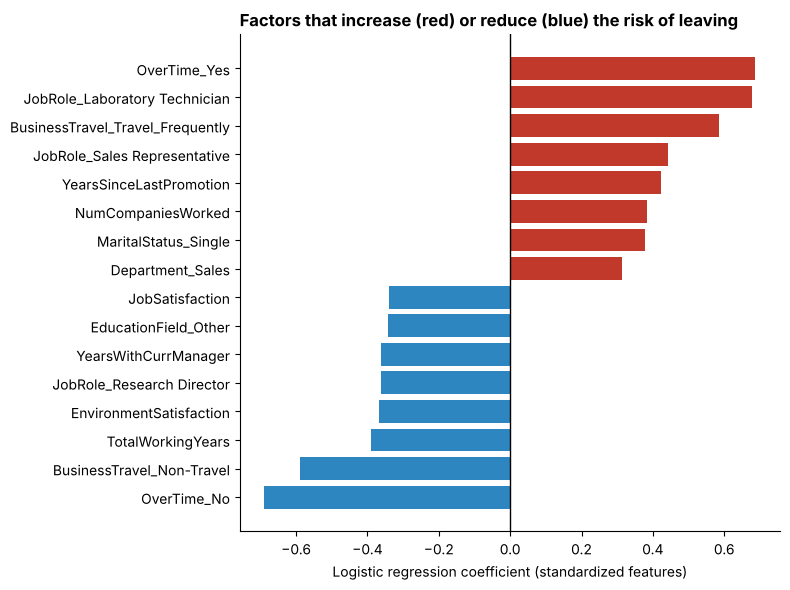

In [17]:
model = best.best_estimator_
coefs = pd.Series(model.named_steps['model'].coef_[0], index=model.named_steps['prep'].get_feature_names_out())
coefs.index = coefs.index.str.replace('num__', '').str.replace('cat__', '')
top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=['#2E86C1' if v < 0 else '#C0392B' for v in top.values])
plt.axvline(0, color='black', linewidth=1)
plt.title('Factors that increase (red) or reduce (blue) the risk of leaving', loc='left', fontweight='bold')
plt.xlabel('Logistic regression coefficient (standardized features)')
for s in ['top', 'right']: plt.gca().spines[s].set_visible(False)
plt.tight_layout()
plt.savefig('../images/risk_factors.png', dpi=150, bbox_inches='tight')
plt.show()

**Main risk factors:** working overtime, frequent business travel, the roles of Laboratory Technician and Sales Representative, more years since the last promotion, more companies worked for previously and being single.

**Protective factors:** no overtime and no business travel (the mirror of the two risk factors above), more total years of experience, higher environment and job satisfaction, and more years with the current manager.

## 9. Conclusions and limitations

**Conclusions**

1. Employee attrition can be ranked with a simple, explainable model: logistic regression reached a test ROC-AUC of 0.81 and captures about 57% of the leavers by contacting 20% of the employees.
2. Overtime is the strongest and most actionable factor: the attrition rate is 30.5% with overtime and 10.4% without. Reviewing workloads, especially for Sales Representatives and Laboratory Technicians, is the first recommended action.
3. A more complex model did not help. After tuning and cross-validation, XGBoost was practically tied with logistic regression (the difference is smaller than the variation between folds), and a single decision tree was clearly worse. Simpler models should be tried first on small tabular datasets.

**Limitations**

- The dataset is fictional and small (1,470 rows, 237 leavers), so the test set has only 47 leavers and the metrics have a wide margin of error. The results show the method, not a real company.
- The data is a single snapshot: it does not show when each person left or what happened before, so the model finds association, not causality. Removing overtime does not guarantee that the same people will stay.
- The data includes `Age`, `Gender` and `MaritalStatus`. In a real use these attributes could create unfair or even illegal decisions, and a model like this should be used to guide support actions for groups of employees, never to penalize an individual. A fairness review and a LGPD/GDPR assessment would be required before any deployment.
- The 0.5 decision threshold is arbitrary. In practice it should be chosen with HR from the cost of a retention action against the cost of losing an employee.

**Next steps:** calibrate the probabilities, choose the threshold from cost estimates, compare the results on a real attrition dataset and test the model on data from a later period.